# Chapter 8: Hierarchical Clustering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.datasets import make_blobs
from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from scipy.stats import mode
import scipy.cluster.hierarchy as shc

## 8.1 Introduction & Motivation

Just like last time, we are passing our data and asking ourself the following question: within the given data, are there any **groups** or **clusters** of datapoints that belong together?

However, this time we will be having a look at hierarchical clustering. This method of clustering starts by looking at each individual datapoint and works it's way up until only one cluster remains. We can then define when to stop merging clusters and what the ideal amount of clusters is.

## 8.2 Problem Setting

Consider an automobile manufacturer that has created prototypes for a new vehicle. Prior to launching this new model, the manufacturer aims to identify which current vehicles on the market closely resemble the prototypes. This involves categorizing vehicles, determining which category is most similar to the new model, and identifying the models it will compete against.

The goal is to employ clustering techniques to identify the most distinct groups of vehicles. This will provide an overview of the current market and assist manufacturers in making informed decisions regarding the introduction of new models.

## 8.3 Model

First, let's have a look at the data.

In [19]:
df = pd.read_csv("Cars.csv")
df = df.drop("type", axis=1)
df = df.drop("partition", axis=1)
df = df.drop("manufact", axis=1)
df = df.drop("model", axis=1)
df.head()

,sales,resale,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales
0,16.919,16.360,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2.828
1,39.384,19.875,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,3.673
2,8.588,29.725,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2.150
3,20.397,22.255,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,3.015
4,18.780,23.555,33.95,2.8,200.0,108.7,76.1,192.0,3.561,18.5,22.0,2.933


In [37]:
auto = pd.read_csv("Cars.csv")
len(auto["model"].unique())

116

In [10]:
df.describe()

,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales,partition
count,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.0
mean,59.112316,18.031538,0.247863,25.969487,3.048718,181.282051,107.326496,71.189744,187.717949,3.324051,17.812821,24.117949,3.401179,0.0
std,75.058933,11.605632,0.433629,14.149699,1.055169,58.591786,8.050588,3.530151,13.849926,0.597177,3.794609,4.404164,1.337862,0.0
min,0.110000,5.160000,0.000000,9.235000,1.000000,55.000000,92.600000,62.600000,149.400000,1.895000,10.300000,15.000000,-2.207000,0.0
25%,16.767000,11.240000,0.000000,16.980000,2.200000,140.000000,102.400000,68.500000,177.500000,2.911000,15.300000,22.000000,2.819000,0.0
50%,32.299000,14.010000,0.000000,21.665000,3.000000,175.000000,107.000000,70.400000,187.800000,3.340000,17.200000,24.000000,3.475000,0.0
75%,76.029000,19.875000,0.000000,29.465000,3.800000,210.000000,111.600000,73.600000,196.500000,3.823000,19.800000,26.000000,4.331000,0.0
max,540.561000,67.550000,1.000000,82.600000,8.000000,450.000000,138.700000,79.300000,224.500000,5.115000,32.000000,45.000000,6.293000,0.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   manufact   117 non-null    object 
 1   model      117 non-null    object 
 2   sales      117 non-null    float64
 3   resale     117 non-null    float64
 4   type       117 non-null    float64
 5   price      117 non-null    float64
 6   engine_s   117 non-null    float64
 7   horsepow   117 non-null    float64
 8   wheelbas   117 non-null    float64
 9   width      117 non-null    float64
 10  length     117 non-null    float64
 11  curb_wgt   117 non-null    float64
 12  fuel_cap   117 non-null    float64
 13  mpg        117 non-null    float64
 14  lnsales    117 non-null    float64
 15  partition  117 non-null    float64
dtypes: float64(14), object(2)
memory usage: 14.8+ KB


#### Question 1: Try and plot a heatmap to further explore the data. There will be two columns you will not be able to plot. Drop them from the heatmap, but do not drop them from your dataframe as we will be needing them later. You can also store them in a seperate dataframe if you wish.

<Axes: >

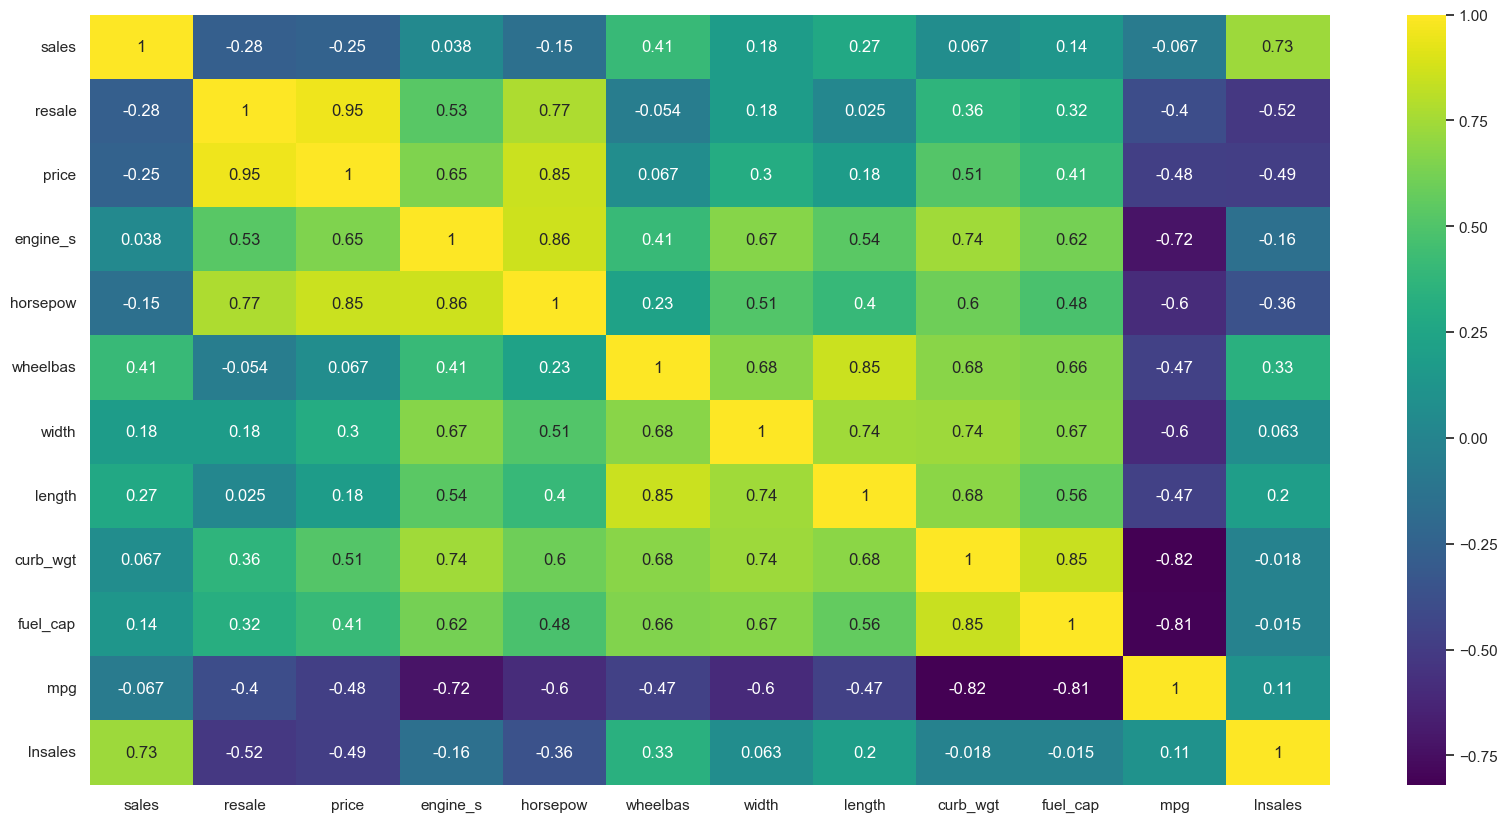

In [8]:
plt.figure(figsize=(20,10))
correlation_matrix = df.select_dtypes(include='number').corr()
sns.heatmap(correlation_matrix, cmap="viridis", annot=True)

#### Question 2: You will notice one column who acts different thant what we are used to. Why is this? Can we use this column? If not, drop the column.

In [ ]:
# partition

## 8.4 Model Evaluation

#### Question 3: Create a dendogram of the model. Remember to exclude the two columns we are keeping to the side on your model. Instead, do some research on the parameters and use one or both of them as labels.

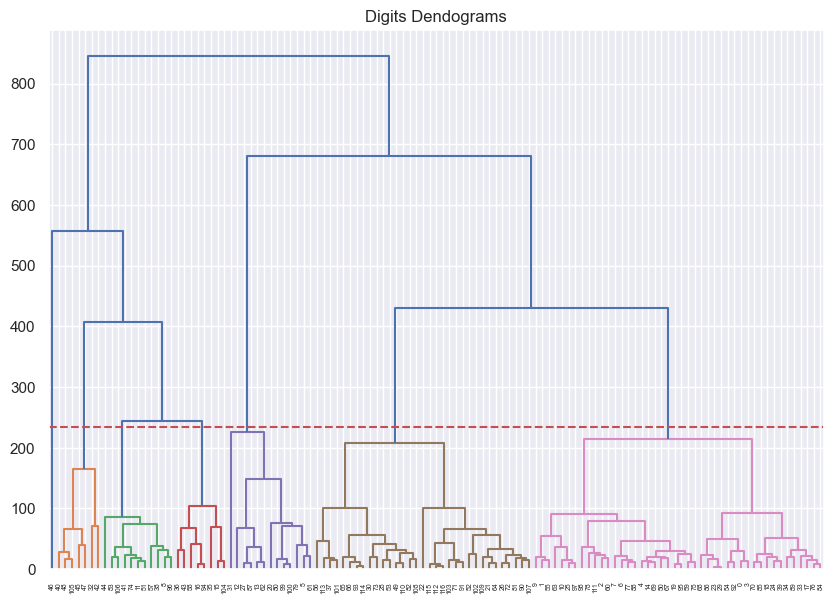

In [47]:
X = df
y = df["mpg"]

plt.figure(figsize=(10, 7))
plt.title("Digits Dendograms")
Z = shc.linkage(X, method='ward')
dend = shc.dendrogram(Z, color_threshold=235)

plt.axhline(y=235, color='r', linestyle='--')

#### Question 4: Think about the proces behind merging two clusters. By looking at the dendrogram, what would you think is a good amount of clusters? Why?

#### Question 5: Calculate the best amount of clusters. Look back to the dendrogram. Does this amount make sense?

In [29]:
Inertia = Z[:,2]
Inertia = Inertia[::-1]

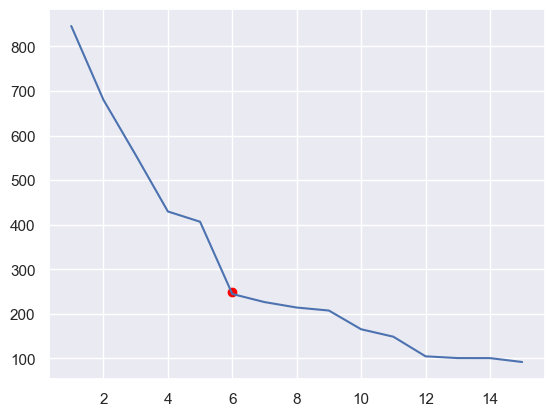

In [34]:
plt.plot(range(1, 16), Inertia[:15])
plt.scatter(6, 250, color="red")

#### Question 6: Draw a line on the dendrogram to visualize the amount of clusters you have found. Do these groups make sense? Are the amount of cars in each cluster balanced? Elaborate.

The amount of clusters are balanced. Based on the size of each cluster.

## 8.4 Exercises

#### Question 1: See section 8.3
#### Question 2: See section 8.3
#### Question 3: See section 8.3
#### Question 4: See section 8.3
#### Question 5: See section 8.3
#### Question 6: See section 8.3
#### Question 7: Consider the cars dataset. Which clustering method would you prefer? Why?

#### Question 8: Calculate the best amount of k for k means. Compare it to the one you calculated earlier. Is it the same or different? Why?

c:\Users\jamey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\jamey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\jamey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\jamey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Window

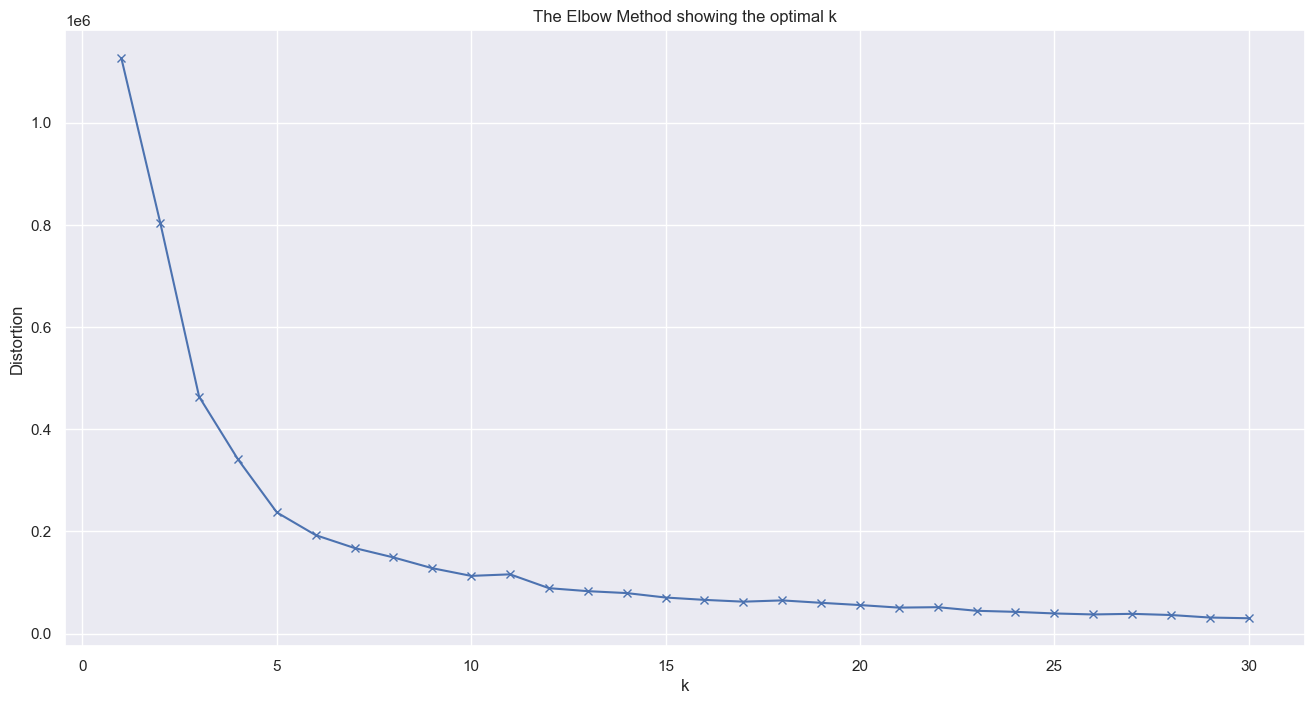

In [55]:
distortions = []
K = range(1,31)
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(X)
    distortions.append(kmeanModel.inertia_)

plt.figure(figsize=(16,8))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method showing the optimal k')

plt.show()

The amount of ideal clusters according to Kmeans and Hierarchical clustering are about the same.

